Dataset Shape: (732, 12)

First 5 Rows:
   Unnamed: 0                              College_Name       State    UG_fee  \
0           0    Indian Institute of Technology Madras   Tamil nadu     75116   
1           1  College of Engineering, Anna University   Tamil nadu     50000   
2           2              NIT Trichy, Tiruchirappalli   Tamil nadu  1,49,250   
3           3          Vellore Institute of Technology   Tamil nadu  1,98,000   
4           4     SRM Engineering College, Kanchipuram   Tamil nadu  2,60,000   

     PG_fee Rating Academic Accommodation Faculty Infrastructure Placement  \
0     23070    8.7        9           7.9     8.7            8.8       8.8   
1     50000    8.4      8.7           7.7     8.1            8.7       8.3   
2     99250    8.5      8.6           7.8     8.2            8.7       8.8   
3  1,83,000    8.3      8.3             8     7.8            8.9       8.5   
4  1,70,000    7.2      6.5           6.6     6.9            7.6       7.1   

  So

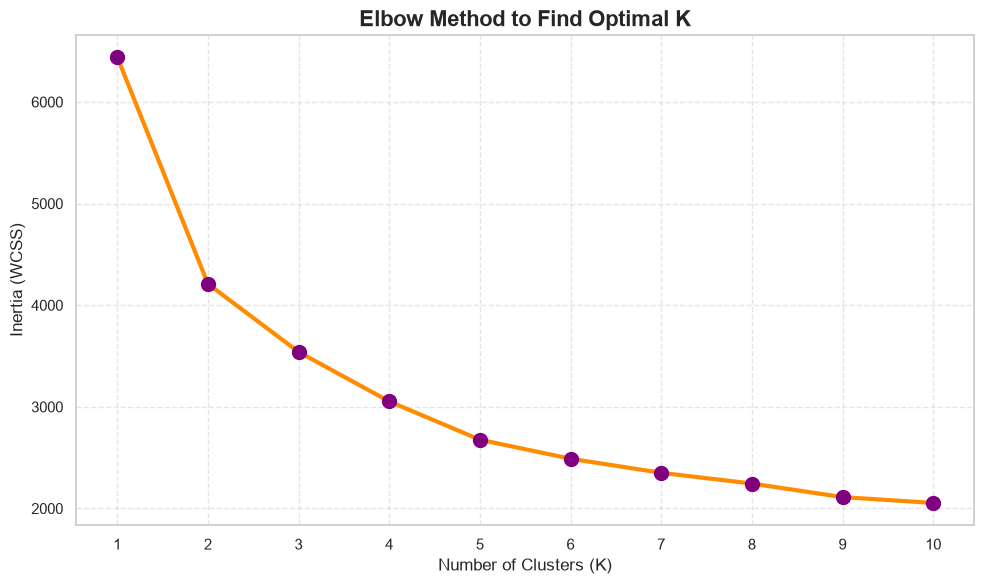


Number of Clusters: 3

Number of Colleges in Each Cluster:
Cluster
0     75
1    283
2    358
Name: count, dtype: int64

Sample Cluster Assignments:
                               College_Name  Cluster
0    Indian Institute of Technology Madras         1
1  College of Engineering, Anna University         1
2              NIT Trichy, Tiruchirappalli         1
3          Vellore Institute of Technology         1
4     SRM Engineering College, Kanchipuram         2
5               SSN College of Engineering         1
6             SASTRA University, Thanjavur         1
7              P.S.G College of Technology         1
8       Thiagarajar College of Engineering         1
9       Coimbatore Institute of Technology         2


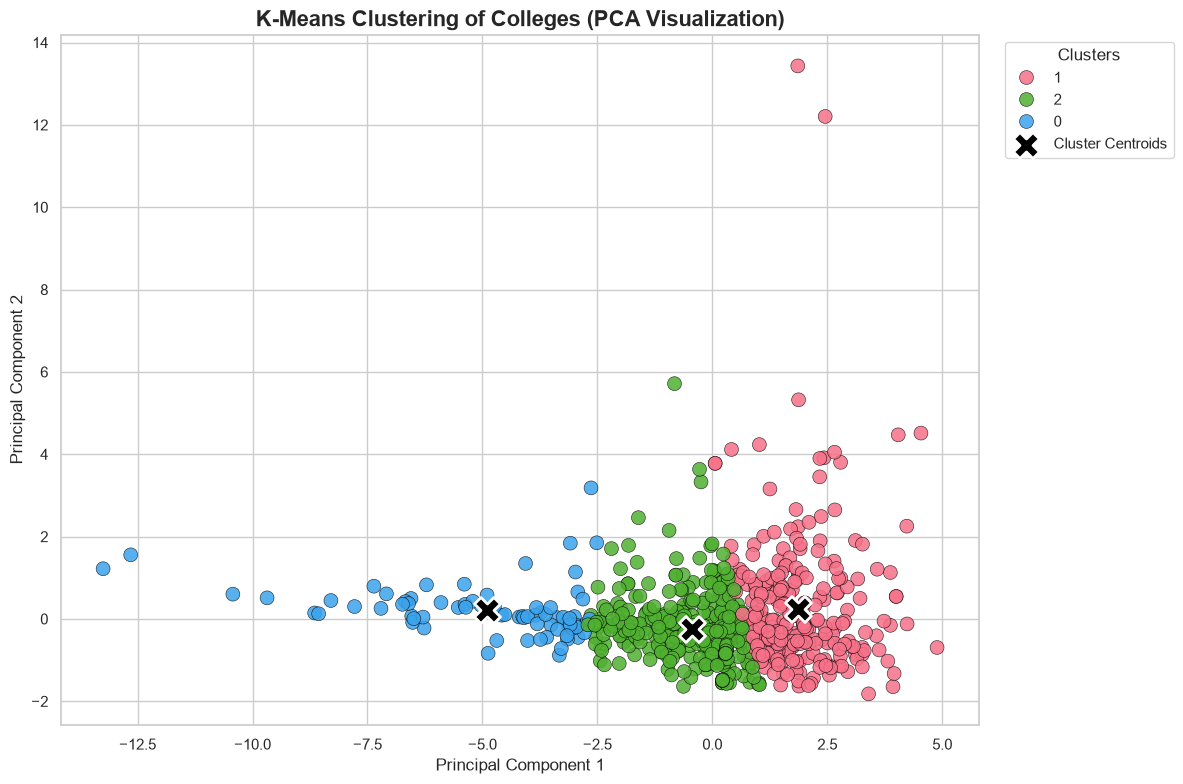


Silhouette Score: 0.2268
A higher silhouette score generally indicates better-separated clusters.

Average Feature Values for Each Cluster:
            UG_fee     PG_fee  Rating  Academic  Accommodation  Faculty  \
Cluster                                                                   
0         88546.53   82992.88    6.12      6.78           5.80     6.65   
1        171545.16  117416.58    8.33      8.50           7.89     8.33   
2        102392.33   78565.45    7.62      7.91           7.13     7.80   

         Infrastructure  Placement  Social_Life  
Cluster                                          
0                  6.49       5.12         6.23  
1                  8.57       8.14         8.40  
2                  7.74       7.24         7.78  

Cluster results saved to KMeans_College_Clusters.csv


In [1]:

# K-Means Clustering on Colleges_Dataset.csv
# Elbow Method, Clustering, and Colourful Visualization

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

# Step 2: Load the dataset
df = pd.read_csv("Colleges_Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# Step 3: Select numerical features
features = [
    "UG_fee",
    "PG_fee",
    "Rating",
    "Academic",
    "Accommodation",
    "Faculty",
    "Infrastructure",
    "Placement",
    "Social_Life"
]

# Step 4: Clean numerical data
X = df[features].copy()

for col in features:
    X[col] = pd.to_numeric(
        X[col].astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
        .replace("--", np.nan),
        errors="coerce"
    )

# Remove columns that contain no usable numeric data
X = X.dropna(axis=1, how="all")

# Remove rows where every selected feature is missing
X = X.dropna(axis=0, how="all")

# Save matching college names and row indices
college_names = df.loc[X.index, "College_Name"].fillna(
    "Unknown College"
).reset_index(drop=True)

# Fill missing values using the median
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Step 5: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nFeatures Used:", list(X.columns))
print("Processed Data Shape:", X_scaled.shape)

# Step 6: Elbow Method to find optimal K
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Colourful Elbow Graph
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia,
    marker="o",
    markersize=9,
    linewidth=3,
    color="darkorange"
)

plt.scatter(
    list(k_values),
    inertia,
    color="purple",
    s=100,
    zorder=3
)

plt.title("Elbow Method to Find Optimal K",
          fontsize=16, fontweight="bold")
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("Inertia (WCSS)", fontsize=12)
plt.xticks(list(k_values))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Step 7: Choose K based on the elbow graph
# Change this value after inspecting the elbow graph.
optimal_k = 3

# Step 8: Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Store cluster assignments
results = pd.DataFrame({
    "College_Name": college_names,
    "Cluster": cluster_labels
})

# Step 9: Display cluster information
print(f"\nNumber of Clusters: {optimal_k}")
print("\nNumber of Colleges in Each Cluster:")
print(results["Cluster"].value_counts().sort_index())

print("\nSample Cluster Assignments:")
print(results.head(10))

# Step 10: Reduce dimensions to 2D using PCA
# PCA is used only to visualize the clusters.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(kmeans.cluster_centers_)

plot_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "Cluster": cluster_labels.astype(str)
})

# Step 11: Colourful Cluster Visualization
plt.figure(figsize=(12, 8))

palette = sns.color_palette("husl", optimal_k)

sns.scatterplot(
    data=plot_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette=palette,
    s=100,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.4
)

# Plot cluster centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=350,
    color="black",
    edgecolor="white",
    linewidth=2,
    label="Cluster Centroids"
)

plt.title(
    "K-Means Clustering of Colleges (PCA Visualization)",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.tight_layout()
plt.show()

# Step 12: Silhouette Score
if 1 < optimal_k < len(X_scaled):
    score = silhouette_score(X_scaled, cluster_labels)
    print(f"\nSilhouette Score: {score:.4f}")
    print("A higher silhouette score generally indicates "
          "better-separated clusters.")

# Step 13: Cluster Profile
profile_data = pd.DataFrame(X_imputed, columns=X.columns)
profile_data["Cluster"] = cluster_labels

print("\nAverage Feature Values for Each Cluster:")
print(profile_data.groupby("Cluster").mean().round(2))

# Step 14: Save results to CSV
results.to_csv("KMeans_College_Clusters.csv", index=False)
print("\nCluster results saved to KMeans_College_Clusters.csv")
